# Plate Reader Data Analysis: Synthesis Rate by Growth-Rate Method

In [1]:
## SHARED CONFIG ##

# Reload configs on each run.
import importlib

import analyse_pr_config
importlib.reload(analyse_pr_config)
from analyse_pr_config import (CONDITION_COLORS, FIGURE_DPI, LABEL_FONTSIZE,
                               LEGEND_FONTSIZE, REPLICATES, TICK_FONTSIZE)


## CONFIG ##

from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D


## PLOTTING ##

plt.rcParams["figure.dpi"] = FIGURE_DPI
plt.rcParams["savefig.dpi"] = FIGURE_DPI

# A4 text width (210 mm page, 25 mm margins) is 160 mm = 6.3 in
FIGSIZE_METHODS = (6.3, 2.6)


## DATA ##

# synthesis rates exported by analyse_pr_synthrate.ipynb, one column set per method
OUT_DIR = Path("out")

# the methods the synthrate CSV carries, SG first as the pipeline's primary
METHODS = {"sg": "Savitzky-Golay", "polyfit": "Polynomial Fit", "window": "Linear Moving window"}
# Colour means the method here, not the condition
METHOD_COLORS = ("black", "tab:purple", "tab:brown")
# x offsets within a condition column, as the bar PDF spreads its replicates
METHOD_OFFSETS = (-0.18, 0.0, 0.18)
# half-width of the mean tick and of the widest column, in axis units
TICK_HALF_WIDTH = 0.26

CONDITIONS = REPLICATES[0]["cond_labels"]
REP_ORDER = tuple(rep["label"] for rep in REPLICATES)

# Every pairing of the three plates; the first of each is the y axis
REPLICATE_PAIRS = (("CD1", "CD2"), ("AL1", "CD1"), ("AL1", "CD2"))
# One scale for all nine panels, on both axes
RPU_AXIS_LIMITS = (0.02, 100)
# Differences under ~2x are within noise
RPU_NOISE_FACTOR = 2.0
FIGSIZE_REPLICATES = (6.3, 2.6)


## pRPU Synthesis Rate by Method

In [2]:
# Read back with keep_default_na=False, na_values=[""]
synthesis_rates = pd.read_csv(OUT_DIR / "analyse_pr_synthrate.csv",
                              keep_default_na=False, na_values=[""])

# pRPU alone: the denominator of every RPU
pRPU = synthesis_rates[synthesis_rates["Group"] == "pRPU"]

print(f"{len(synthesis_rates)} rows read, {len(pRPU)} pRPU wells "
      f"({len(pRPU) // len(REP_ORDER)} per replicate, one per condition)")

# Circuits alone for the replicate-agreement figure
circuits = synthesis_rates[synthesis_rates["Group"].str.startswith("Circuit")]


1140 rows read, 12 pRPU wells (4 per replicate, one per condition)


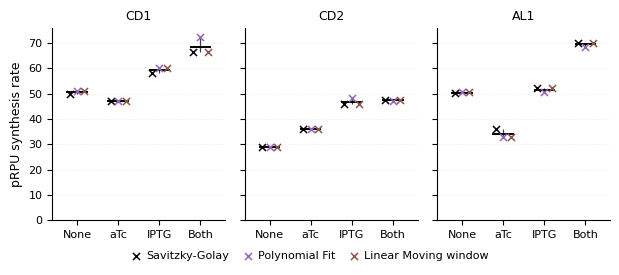

CV of pRPU synthesis rate across the four conditions, % (lower is steadier)

     Savitzky-Golay  Polynomial Fit  Linear Moving window
CD1            15.8            19.3                  15.5
CD2            22.5            23.4                  22.5
AL1            26.8            28.6                  29.5


In [3]:
# pRPU's synthesis rate under each method, one panel per replicate
# pRPU is constitutive, so the four columns should read alike
values = np.array([[[float(pRPU[(pRPU["Rep"] == rep) & (pRPU["Condition"] == condition)]
                           [f"synthesis_rate_{method}"].iloc[0])
                     for condition in CONDITIONS]
                    for method in METHODS]
                   for rep in REP_ORDER])
centres = np.arange(len(CONDITIONS))

fig, axes = plt.subplots(1, len(REP_ORDER), figsize=FIGSIZE_METHODS, sharey=True)
for rep_i, (ax, rep) in enumerate(zip(axes, REP_ORDER)):
    rep_values = values[rep_i]
    ax.vlines(centres, rep_values.min(axis=0), rep_values.max(axis=0), color="black", lw=0.9,
              alpha=0.75, zorder=2)
    ax.hlines(rep_values.mean(axis=0), centres - TICK_HALF_WIDTH, centres + TICK_HALF_WIDTH,
              color="black", lw=1.4, zorder=3)
    for method_i, label in enumerate(METHODS.values()):
        ax.scatter(centres + METHOD_OFFSETS[method_i], rep_values[method_i], marker="x",
                   color=METHOD_COLORS[method_i], s=26, linewidths=1.1, zorder=4, label=label)

    ax.set_xticks(centres)
    ax.set_xticklabels(CONDITIONS)
    ax.set_xlim(-0.6, len(CONDITIONS) - 0.4)
    ax.set_title(rep, fontsize=LABEL_FONTSIZE)
    ax.tick_params(which="both", labelsize=TICK_FONTSIZE)
    ax.grid(True, axis="y", ls=":", alpha=0.3, linewidth=0.5)
    for spine in ("top", "right"):
        ax.spines[spine].set_visible(False)

# headroom keeps the highest marker clear of the top spine
axes[0].set_ylim(0, values.max() * 1.05)
axes[0].set_ylabel("pRPU synthesis rate", fontsize=LABEL_FONTSIZE)
fig.legend(*axes[0].get_legend_handles_labels(), fontsize=LEGEND_FONTSIZE, loc="lower center",
           ncol=len(METHODS), frameon=False, handlelength=1.0, handletextpad=0.4,
           columnspacing=1.2, bbox_to_anchor=(0.5, -0.06))
plt.tight_layout()
plt.show()

# Spread across the four columns, per method
spread = pd.DataFrame(
    {label: {rep: 100 * pRPU[pRPU["Rep"] == rep][f"synthesis_rate_{method}"].std(ddof=1)
             / pRPU[pRPU["Rep"] == rep][f"synthesis_rate_{method}"].mean()
             for rep in REP_ORDER}
     for method, label in METHODS.items()})
print("CV of pRPU synthesis rate across the four conditions, % (lower is steadier)\n")
print(spread.round(1).to_string())


## RPU Agreement Between Plates

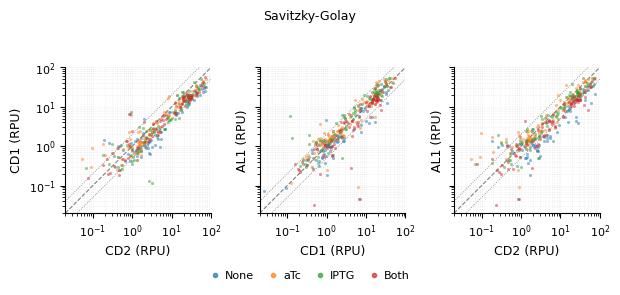

Savitzky-Golay
   CD1/CD2 n=349 median 1.61x within 2x 72% (19 non-positive, 1 off-scale)
   AL1/CD1 n=357 median 1.35x within 2x 84% (10 non-positive, 2 off-scale)
   AL1/CD2 n=350 median 1.48x within 2x 73% (17 non-positive, 3 off-scale)


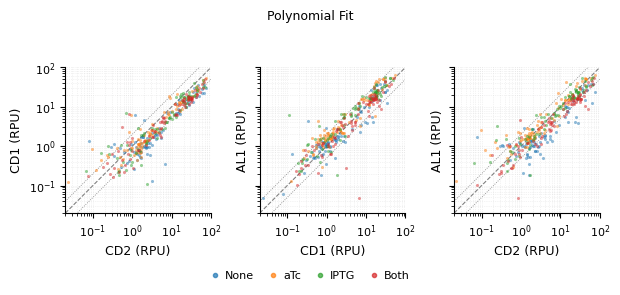

Polynomial Fit
   CD1/CD2 n=348 median 1.72x within 2x 68% (20 non-positive, 1 off-scale)
   AL1/CD1 n=351 median 1.42x within 2x 82% (16 non-positive, 0 off-scale)
   AL1/CD2 n=346 median 1.43x within 2x 74% (21 non-positive, 2 off-scale)


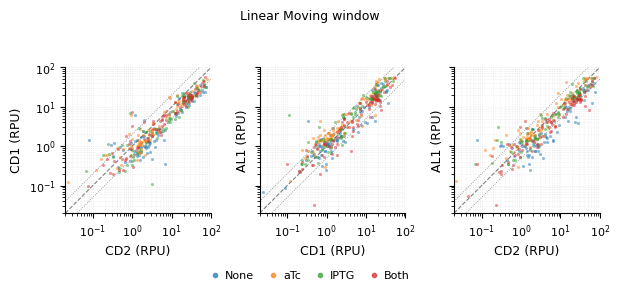

Linear Moving window
   CD1/CD2 n=347 median 1.69x within 2x 69% (21 non-positive, 1 off-scale)
   AL1/CD1 n=353 median 1.37x within 2x 80% (14 non-positive, 2 off-scale)
   AL1/CD2 n=348 median 1.48x within 2x 72% (19 non-positive, 4 off-scale)


In [4]:
# RPU agreement: each plate against each other, one figure per method
# Only cells positive on both plates are drawn; the rest are counted
for method, label in METHODS.items():
    grid = circuits.pivot_table(index=["Group", "Condition"], columns="Rep",
                                values=f"RPU_{method}")
    fig, axes = plt.subplots(1, len(REPLICATE_PAIRS), figsize=FIGSIZE_REPLICATES, sharey=True)
    reported = []

    for ax, (y_rep, x_rep) in zip(axes, REPLICATE_PAIRS):
        pair = grid[[y_rep, x_rep]].dropna()
        drawn = pair[(pair > 0).all(axis=1)]
        for cond_i, condition in enumerate(CONDITIONS):
            points = drawn[drawn.index.get_level_values("Condition") == condition]
            ax.scatter(points[x_rep], points[y_rep], s=5, alpha=0.5, linewidths=0,
                       color=CONDITION_COLORS[cond_i])

        ax.plot(RPU_AXIS_LIMITS, RPU_AXIS_LIMITS, color="gray", ls="--", lw=0.8, zorder=0)
        # the band within which two readings cannot be told apart
        for factor in (RPU_NOISE_FACTOR, 1 / RPU_NOISE_FACTOR):
            ax.plot(RPU_AXIS_LIMITS, [limit * factor for limit in RPU_AXIS_LIMITS],
                    color="gray", ls=":", lw=0.6, zorder=0)

        ax.set_xscale("log")
        ax.set_yscale("log")
        ax.set_xlim(*RPU_AXIS_LIMITS)
        ax.set_ylim(*RPU_AXIS_LIMITS)
        ax.set_aspect("equal")
        ax.set_xlabel(f"{x_rep} (RPU)", fontsize=LABEL_FONTSIZE)
        ax.set_ylabel(f"{y_rep} (RPU)", fontsize=LABEL_FONTSIZE)
        ax.tick_params(which="both", labelsize=TICK_FONTSIZE)
        ax.grid(True, which="both", ls=":", alpha=0.3, linewidth=0.5)
        for spine in ("top", "right"):
            ax.spines[spine].set_visible(False)

        fold = np.abs(np.log2(drawn[y_rep] / drawn[x_rep]))
        off_scale = int((~drawn.apply(
            lambda column: column.between(*RPU_AXIS_LIMITS)).all(axis=1)).sum())
        reported.append(f"{y_rep}/{x_rep} n={len(drawn)} "
                        f"median {2 ** fold.median():.2f}x "
                        f"within {RPU_NOISE_FACTOR:.0f}x {100 * (fold < 1).mean():.0f}% "
                        f"({len(pair) - len(drawn)} non-positive, {off_scale} off-scale)")

    condition_legend = [Line2D([], [], marker="o", ls="", color=CONDITION_COLORS[i],
                               markersize=3, alpha=0.7, label=condition)
                        for i, condition in enumerate(CONDITIONS)]
    fig.legend(handles=condition_legend, fontsize=LEGEND_FONTSIZE, loc="lower center",
               ncol=len(CONDITIONS), frameon=False, handlelength=1.0, handletextpad=0.4,
               # clear of the per-panel x labels, which square axes push down
               columnspacing=1.2, bbox_to_anchor=(0.5, -0.10))
    fig.suptitle(label, fontsize=LABEL_FONTSIZE)
    plt.tight_layout()
    plt.show()

    print(f"{label}\n   " + "\n   ".join(reported))
